In [53]:
from IPython.display import HTML

HTML("<h1>Task-2: Unemployment Analysis</h1>")


In [1]:
# importing libraries
import pandas as pd

In [2]:
import numpy as np

In [3]:
import seaborn as sns

In [5]:
import matplotlib.pyplot as plt

In [6]:
df=pd.read_csv("Unemployment in India.csv")

In [7]:
df

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [9]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [10]:
df.tail()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
767,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [12]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [13]:
df.shape

(768, 7)

In [14]:
# preprocessing
df.isnull()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
763,True,True,True,True,True,True,True
764,True,True,True,True,True,True,True
765,True,True,True,True,True,True,True
766,True,True,True,True,True,True,True


In [15]:
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [16]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.lower()

df.head()


,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [30]:
df['date'] = pd.to_datetime(df['date'], errors='coerce', dayfirst=True)
df = df.dropna(subset=['date'])
df = df.sort_values('date')


In [35]:
df['estimated_unemployment_rate_(%)'] = pd.to_numeric(df['estimated_unemployment_rate_(%)'], errors='coerce')
df['estimated_employed'] = pd.to_numeric(df['estimated_employed'], errors='coerce')
df['estimated_labour_participation_rate_(%)'] = pd.to_numeric(df['estimated_labour_participation_rate_(%)'], errors='coerce')


In [36]:
df = df.dropna(subset=['estimated_unemployment_rate_(%)'])


In [38]:
print("Shape:", df.shape)
print(df.describe())
print("Date range:", df['date'].min(), "to", df['date'].max())


Shape: (740, 7)
                                date  estimated_unemployment_rate_(%)  \
count                            740                       740.000000   
mean   2019-12-12 18:36:58.378378496                        11.787946   
min              2019-05-31 00:00:00                         0.000000   
25%              2019-08-31 00:00:00                         4.657500   
50%              2019-11-30 00:00:00                         8.350000   
75%              2020-03-31 00:00:00                        15.887500   
max              2020-06-30 00:00:00                        76.740000   
std                              NaN                        10.721298   

       estimated_employed  estimated_labour_participation_rate_(%)  
count        7.400000e+02                               740.000000  
mean         7.204460e+06                                42.630122  
min          4.942000e+04                                13.330000  
25%          1.190404e+06                         

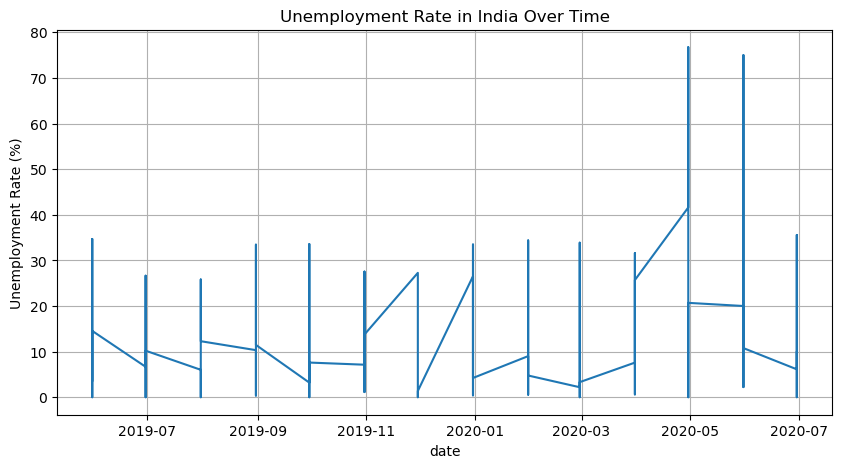

In [40]:
# visualization
plt.figure(figsize=(10,5))
plt.plot(df['date'], df['estimated_unemployment_rate_(%)'])
plt.title("Unemployment Rate in India Over Time")
plt.xlabel("date")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.show()


In [41]:
# COVID-19 Impact ANALYSIS
covid_start = pd.to_datetime("2020-03-01")
covid_end = pd.to_datetime("2021-03-31")


In [43]:
pre_covid = df[df['date'] < covid_start]
during_covid = df[(df['date'] >= covid_start) & (df['date'] <= covid_end)]
post_covid = df[df['date'] > covid_end]


In [45]:
print("Pre-COVID avg unemployment:", pre_covid['estimated_unemployment_rate_(%)'].mean())
print("During-COVID avg unemployment:", during_covid['estimated_unemployment_rate_(%)'].mean())
print("Post-COVID avg unemployment:", post_covid['estimated_unemployment_rate_(%)'].mean())


Pre-COVID avg unemployment: 9.509533582089553
During-COVID avg unemployment: 17.774362745098042
Post-COVID avg unemployment: nan


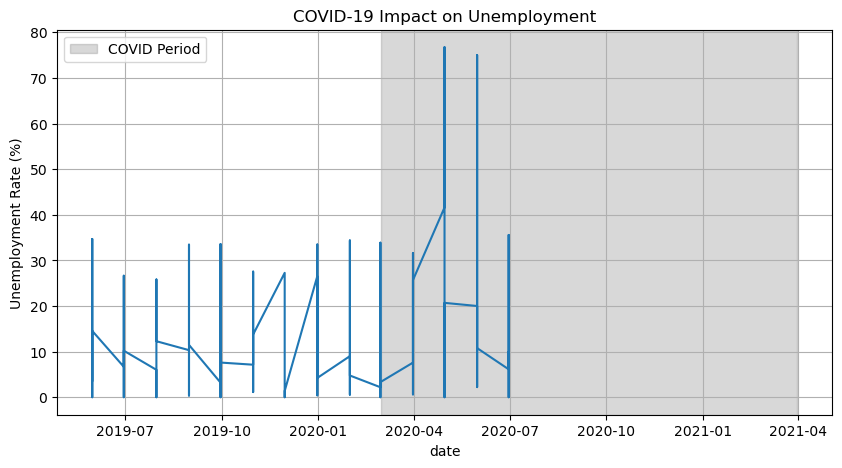

In [47]:
plt.figure(figsize=(10,5))
plt.plot(df['date'], df['estimated_unemployment_rate_(%)'])
plt.axvspan(covid_start, covid_end, color='grey', alpha=0.3, label='COVID Period')
plt.title("COVID-19 Impact on Unemployment")
plt.xlabel("date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.grid(True)
plt.show()


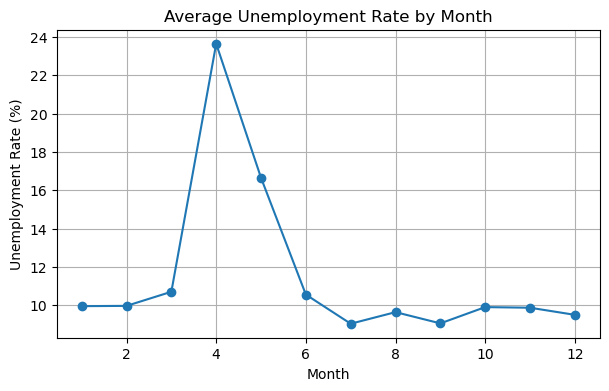

In [48]:
df['Month'] = df['date'].dt.month

monthly_avg = df.groupby('Month')['estimated_unemployment_rate_(%)'].mean()

plt.figure(figsize=(7,4))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o')
plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.show()


In [50]:
region_avg = df.groupby('region')['estimated_unemployment_rate_(%)'].mean().sort_values(ascending=False)
print(region_avg.head(10))


region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: estimated_unemployment_rate_(%), dtype: float64
